# Catalina Island Invasive Species Mapping and Prediction




## Project Proposal Summary


We will be looking at Catalina Island off the coast of LA County identifing the locations of invasive plant species. To do so, both supervised and unsupervised classification methods are used to determine the locations of invasive plant species on the island outside of areas already surveyed on foot. The supervised method will be Classification and Regression Trees(CART) and the unsupervised will be K-means Clustering.


### Citations:

#### K-Mean Clustering:
Zhang, S., Guo, J., & Wang, Z. (2019). Combing K-means Clustering and Local Weighted Maximum Discriminant Projections for Weed Species Recognition. Frontiers in Computer Science, 1. https://doi.org/10.3389/fcomp.2019.00004

Chowdhury, S., Hamerly, G., & McGarrity, M. (2024). Active Learning Strategy Using Contrastive Learning and K-means for Aquatic Invasive Species Recognition. 2024 IEEE/CVF Winter Conference on Applications of Computer Vision Workshops (WACVW), 848–858. https://doi.org/10.1109/WACVW60836.2024.00097

Detka, J., Coyle, H., Gomez, M., & Gilbert, G. S. (2023). A Drone-Powered Deep Learning Methodology for High Precision Remote Sensing in California’s Coastal Shrubs. Drones, 7(7), 421. https://doi.org/10.3390/drones7070421

Rakgoale, P. B., & Ngetar, S. N. (2024). Detecting Invasive Alien Plant Species Using Remote Sensing, Machine Learning and Deep Learning. Journal of Sensors, 2024(1), 8854675. https://doi.org/10.1155/2024/8854675

Ikotun, A. M., & Ezugwu, A. E. (2022). Boosting k-means clustering with symbiotic organisms search for automatic clustering problems. PLOS ONE, 17(8), e0272861. https://doi.org/10.1371/journal.pone.0272861

K-means Clustering Tutorials:

- https://www.geeksforgeeks.org/machine-learning/k-means-clustering-introduction/

- https://www.kaggle.com/code/prashant111/k-means-clustering-with-python

- https://realpython.com/k-means-clustering-python/



#### CART:
Moisen, G. G. (2008). Classification and regression trees. Encyclopedia of Ecology, 582–588. https://doi.org/10.1016/b978-008045405-4.00149-x


Pyšek, P., Jarošík, V., Hulme, P. E., Pergl, J., Hejda, M., Schaffner, U., & Vilà, M. (2012, May). A global assessment of invasive plant impacts on resident species, communities and ecosystems: The interaction of impact measures, invading species’ traits and environment. Global Change Biology. https://pmc.ncbi.nlm.nih.gov/articles/PMC3597245/

CART Tutorials:
- https://www.geeksforgeeks.org/machine-learning/implementing-cart-classification-and-regression-tree-in-python/

- https://medium.com/@cristianleo120/classification-and-regression-trees-cart-implementation-from-scratch-in-python-89efa31ad9a6


- https://www.kaggle.com/code/bahaulug/classification-and-regression-tree-cart

- https://andrewcharlesjones.github.io/journal/cart.html

- https://mbrenndoerfer.com/writing/cart-decision-trees-classification-regression-mathematical-foundations-python-implementation



## Datasets and Sources

### LARIAC7 (4 inch resolution)

  - Sourced from CSULB Geography Department
    - Misc. relevant URLs:
        - LA County Aerial 2023 Imagery: https://egis-lacounty.hub.arcgis.com/maps/b301429f8bc1469bb2bbd5a6c3330abe/explore?location=33.310370%2C-118.416133%2C10
        - LA County Aerial 2023 (Labels): https://egis-lacounty.hub.arcgis.com/maps/34224d8a27c142cf825c4187185c33fe/explore?location=33.417151%2C-118.437291%2C-1
        - LARIAC4 2016 Contours - Vector Tiles: https://egis-lacounty.hub.arcgis.com/maps/64eb8ddac0954276b0b0ea89b7a8a539/explore?location=33.386338%2C-118.330200%2C10
        - Catalina Vector Map https://apps.gis.lacounty.gov/static/hub/lariac_documents/LARIAC2_projectAreas.zip

        - 4-inch ortho imagery 2023
            - https://lariac-lacounty.hub.arcgis.com/pages/lariac7-documents-data
            - https://apps.gis.lacounty.gov/static/hub/lariac_documents/LARIAC1_4_inch_grid_500ft.zip
    
- CRS
    - EPSG: 6424

- Modifications Needed:
    - Normalization
    - Clip out extraneous datapoints not on the island
    - Reprojected if I can't reproject other data first.

- Important Fields:
    - I'll want the NIR, Red, Green, and Blue bands for NDVI and imagery training/analysis.
    - Image collection date

- Files are GeoTiffs and I have access to orthorectified versions of the data,

### LIDAR and DEM

  - Sourced from USDA National Map Downloader. 
      - https://apps.nationalmap.gov/downloader/

CRS
- 2016 LIDAR EPSG: 2229 (Unused but available)
- 2025 LIDAR EPSG: 6340
- DEM EPSG: 6340

Modifications
- Reprojection to match the LARIAC data
- Clip to remove anything that's not Catalina Island
- Normalization
  - High resolution DEM of the island for normalization


### Training Data: Vegetation and Background Shapefiles 

- Sourced from client

CRS
- EPSG 3857

Modifications
- Reprojection to LARIAC CRS
- Data needs to be cleaned
  - dates need to be standardized
  - unwanted columns removed
  - remove unwanted dates
  - potentially clean up and merge treatment columns for future analysis (as time permits)


# Data Prep

Computer Specifications:
- Processor: AMD Ryzen 7 5800X 8-Core Processor, 3801 Mhz, 8 Core(s), 16 Logical Processor(s)
- GPU: ASUS ROG STRIX B550-F GAMING (WI-FI) 24GB GPU memory
- RAM: 36GB
Windows 10
Python 3.11.15 in a Conda environment

### Environment Setup

In [1]:
import gc
import json
import os
import shutil
import time
from pathlib import Path

import cv2
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdal
import rasterio
from osgeo import gdal
from requests.adapters import HTTPAdapter
from requests.packages.urllib3.util.retry import Retry
from scipy.ndimage import generic_filter
from shapely.geometry import Point, box
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from rasterio.coords import BoundingBox
from rasterio.enums import Resampling
from rasterio.features import geometry_mask, geometry_window
from rasterio.mask import mask
from rasterio.merge import merge
from rasterio.vrt import WarpedVRT
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling
)
from rasterio.windows import Window, from_bounds


### Create Folder Directory

Additional folders can be made for any other data you want to include. 

Total disk space needed: ~2TB to be safe

#### Warning
Folder paths in the notebook do not follow this directory. Be sure to update all paths throughout when using

In [ ]:
from pathlib import Path

root = Path(r"E:\Invasive_Species_GIS_Project")

folders = [
    "LARIAC7/Raw",
    "LARIAC7/Normalized",
    "LARIAC7/Clipped",
    "LARIAC7/NDVI"
    "LARIAC7/RGB_HSV",
    "LARIAC7/NRG_HSV",

    "LIDAR_2025/Raw",
    "LIDAR_2025/Normalized",
    "LIDAR_2025/CHM",
    "LIDAR_2025/Reprojected",
    "LIDAR_2025/Clipped",
    "LIDAR_2025/Mosaic",

    "DEM/Raw",
    "DEM/Reprojected",
    "DEM/Clipped",

    "Shapefiles/Raw",
    "Shapefiles/Cleaned",
    "Shapefiles/Reprojected",

    "Model_Outputs/K_Means",
    "Model_Outputs/CART_G_linifolia",
    "Model_Outputs/CART_F_vulgare",
    "Model_Outputs/CART_P_aquatica",
        
]

for folder in folders:
    (root / folder).mkdir(parents=True, exist_ok=True)

print("GIS project folders created.")

GIS project folders created.


## Reproject All the Things

I did things really inefficiently, so here you should  convert everything to the same CRS to make future processing more straight forward. I've included some of the code so you can adjust differnt things as needed.

### Reproject WMU, background and species Shapefile CRS to EPSG:6424 coordinate reference system

In [ ]:

def reproject_shapefile_with_encoding(input_shp, output_shp, target_crs="EPSG:6424"):
    input_shp = Path(input_shp)
    output_shp = Path(output_shp)
    output_shp.parent.mkdir(parents=True, exist_ok=True)

    encodings = ["latin1", "cp1252", "ISO-8859-1"]

    for enc in encodings:
        try:
            print("Trying encoding:", enc)

            gdf = gpd.read_file(input_shp, encoding=enc)

            if gdf.crs is None:
                raise ValueError("Input shapefile has no CRS defined")

            gdf = gdf.to_crs(target_crs)
            gdf.to_file(output_shp, encoding="utf-8")

            print("Saved:", output_shp)
            return

        except Exception as e:
            print("Failed with", enc, ":", e)

    print("Could not read shapefile with tested encodings.")

In [ ]:
reproject_shapefile_with_encoding(
    input_shp=r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\NAD83\G_linifolia",
    output_shp=r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\epsg_6424\G_linifolia.shp")

Trying encoding: latin1
Saved: G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\epsg_6424\G_linifolia.shp


#### DTM was made in ArcGIS Pro by creating a mosaic from the DEM data available on the National Map Downloader

In [ ]:
#### Reproject DTM

def reproject_dtm_to_epsg6424(input_dtm, output_dtm):
    input_dtm = Path(input_dtm)
    output_dtm = Path(output_dtm)

    output_dtm.parent.mkdir(parents=True, exist_ok=True)

    dst_crs = "EPSG:6424"

    with rasterio.open(input_dtm) as src:
        transform, width, height = calculate_default_transform(
            src.crs,
            dst_crs,
            src.width,
            src.height,
            *src.bounds
        )

        kwargs = src.meta.copy()
        kwargs.update({
            "crs": dst_crs,
            "transform": transform,
            "width": width,
            "height": height,
            "compress": "lzw",
            "BIGTIFF": "YES"
})

        with rasterio.open(output_dtm, "w", **kwargs) as dst:
            for band in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, band),
                    destination=rasterio.band(dst, band),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=dst_crs,
                    resampling=Resampling.bilinear
                )

    print("Saved reprojected DTM:", output_dtm)

reproject_dtm_to_epsg6424(
    input_dtm=r"D:\AAFinal_Project_cut_folders\DTM_epsg6340_clip.tif",
    output_dtm=r"D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif"
)


Saved reprojected DTM: D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif


Reproject Shape Files

In [ ]:
# Input shapefile
input_shp = r"G:\473_588_Final_Project\shapes\drawn_background.shp"

# Output shapefile
output_shp = r"G:\473_588_Final_Project\shapes\species_cleaned\background_epsg6424.shp"

# Read shapefile
gdf = gpd.read_file(input_shp)

# Check original CRS
print("Original CRS:", gdf.crs)

# Reproject to EPSG:6424
gdf_reprojected = gdf.to_crs(epsg=6424)

# Save new shapefile
gdf_reprojected.to_file(output_shp)

print("Finished reprojection.")
print("New CRS:", gdf_reprojected.crs)

Original CRS: EPSG:8718
Finished reprojection.
New CRS: EPSG:6424


# 4 inch LARIAC7 Imagery

### Read in LARIAC files

In [ ]:
## Load LARIAC Training Data (Including Nested Folders)


# Folder containing LARIAC 7 GeoTIFFs
L7_folder = Path(r"G:/473_588_Final_Project/LARIAC_Data/LARIAC_7")

# Dictionary to store file info
L7_files = {}

if L7_folder.exists():
    print("Folder found:", L7_folder)

    # Find tif/tiff files recursively
    tif_files = list(L7_folder.rglob("*.tif")) + list(L7_folder.rglob("*.TIF")) + \
                list(L7_folder.rglob("*.tiff")) + list(L7_folder.rglob("*.TIFF"))

    print("Found", len(tif_files), "TIF file(s)")

    for tif_path in tif_files:
        rel_path = tif_path.relative_to(L7_folder)

        try:
            with rasterio.open(tif_path) as src:
                # Do NOT read full data yet, just store metadata
                L7_files[str(rel_path)] = {
                    "filepath": str(tif_path),
                    "profile": src.profile.copy(),
                    "crs": src.crs,
                    "bounds": src.bounds,
                    "bands": src.count,
                    "height": src.height,
                    "width": src.width,
                    "shape": (src.count, src.height, src.width)
                }

                print("Loaded metadata:", rel_path)
                print("  Shape:", (src.count, src.height, src.width))
                print("  CRS:", src.crs)

        except Exception as e:
            print("Error reading:", rel_path)
            print(e)

    print("Successfully indexed", len(L7_files), "file(s)")

else:
    print("Folder not found:", L7_folder)

Folder found: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7
Found 854 TIF file(s)
Loaded metadata: L7_6434_1570b.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6434_1570c.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6374_1628d.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6434_1575a.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6374_1633d.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6440_1570b.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6434_1575b.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6376_1622b.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6445_1570b.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6440_1570c.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6434_1575c.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG:6424
Loaded metadata: L7_6376_1622c.tif
  Shape: (4, 8250, 8250)
  CRS: EPSG

KeyboardInterrupt: 

### Normalize LARIAC Imagery

In [ ]:
############################# NEED THIS FOR ALL FUNCTIONS THAT CREATE NEW TIF FILES ###################
# Function to copy associated files (like .tfw, .aux.xml, .ovr) from input TIF to output TIF if they exist to maintain geospatial metadata and auxiliary information

def copy_associated_files(input_tif, output_tif):
    input_tif = Path(input_tif)
    output_tif = Path(output_tif)

    sidecar_patterns = [
        input_tif.stem + ".tfw",
        input_tif.name + ".aux.xml",
        input_tif.stem + ".aux.xml",
        input_tif.name + ".ovr",
        input_tif.stem + ".ovr",
        input_tif.stem + ".xml",
        input_tif.stem + ".prj"
    ]

    for sidecar_name in sidecar_patterns:
        sidecar = input_tif.parent / sidecar_name

        if sidecar.exists():
            if sidecar_name.startswith(input_tif.name):
                new_name = output_tif.name + sidecar_name[len(input_tif.name):]
            else:
                new_name = output_tif.stem + sidecar_name[len(input_tif.stem):]

            shutil.copy2(sidecar, output_tif.parent / new_name)
            print("Copied:", sidecar.name)

In [ ]:
# Normalize a TIF file using a windowed approach to handle large files without loading everything into memory
# min-max normalization: (value - min) / (max - min)
def normalize_tif_per_raster_windowed(input_tif, output_tif):

    input_tif = Path(input_tif)
    output_tif = Path(output_tif)
    output_tif.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(input_tif) as src:
        profile = src.profile.copy()
        nodata = src.nodata

        global_min = np.inf
        global_max = -np.inf

        # pass 1: find min/max
        for _, window in src.block_windows(1):
            data = src.read(window=window).astype("float32")

            mask = np.isfinite(data)
            if nodata is not None:
                mask = mask & (data != nodata)

            if np.any(mask):
                global_min = min(global_min, data[mask].min())
                global_max = max(global_max, data[mask].max())

        profile.update(dtype="float32", nodata=-9999, compress="lzw")

        # pass 2: normalize + write
        with rasterio.open(output_tif, "w", **profile) as dst:
            for _, window in src.block_windows(1):
                data = src.read(window=window).astype("float32")

                mask = np.isfinite(data)
                if nodata is not None:
                    mask = mask & (data != nodata)

                norm = np.full(data.shape, -9999, dtype="float32")

                if global_max != global_min:
                    norm[mask] = (data[mask] - global_min) / (global_max - global_min)
                else:
                    norm[mask] = 0

                dst.write(norm, window=window)

    
    copy_associated_files(input_tif, output_tif)

    print("Saved:", output_tif)

In [ ]:
# Batch process all TIF files in the input folder (including nested folders) and save normalized versions to the output folder while maintaining directory structure

input_folder = Path(r'G:\473_588_Final_Project\LARIAC_Data\LARIAC_7')
output_folder = Path(r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm")

for tif in input_folder.rglob("*"):
    if tif.suffix.lower() in [".tif", ".tiff"]:
        relative_path = tif.relative_to(input_folder)
        output_path = output_folder / relative_path
        output_path = output_path.with_name(f"{tif.stem}_norm.tif")

        output_path.parent.mkdir(parents=True, exist_ok=True)

        normalize_tif_per_raster_windowed(
            input_tif=str(tif),
            output_tif=str(output_path)
        )

Copied: L7_6434_1570b.tfw
Copied: L7_6434_1570b.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6434_1570b_norm.tif
Copied: L7_6434_1570c.tfw
Copied: L7_6434_1570c.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6434_1570c_norm.tif
Copied: L7_6374_1628d.tfw
Copied: L7_6374_1628d.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6374_1628d_norm.tif
Copied: L7_6434_1575a.tfw
Copied: L7_6434_1575a.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6434_1575a_norm.tif
Copied: L7_6374_1633d.tfw
Copied: L7_6374_1633d.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6374_1633d_norm.tif
Copied: L7_6440_1570b.tfw
Copied: L7_6440_1570b.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6440_1570b_norm.tif
Copied: L7_6434_1575b.tfw
Copied: L7_6434_1575b.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6434_1575b_norm.tif
Copied: L7_63

In [ ]:
# Quick check: print CRS and transform of one of the normalized files to verify metadata is preserved
with rasterio.open(r'G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6466_1580a_norm.tif') as src:
    print(src.crs)
    print(src.transform)

EPSG:6424
| 0.32, 0.00, 6466480.00|
| 0.00,-0.32, 1583280.00|
| 0.00, 0.00, 1.00|


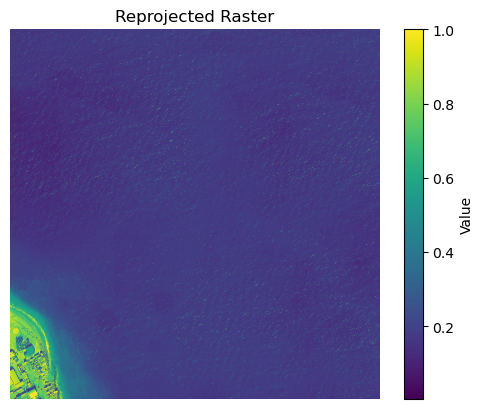

In [ ]:

tif_path = r'G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm\L7_6466_1580a_norm.tif'

with rasterio.open(tif_path) as src:
    data = src.read(1)

plt.imshow(data, cmap="viridis")
plt.colorbar(label="Value")
plt.title("Reprojected Raster")
plt.axis("off")
plt.show()

### Read in WMU shapefile and Clip Rasters

In [ ]:

def clip_tif_with_shp(input_tif, input_shp, output_tif):
    input_tif = Path(input_tif)
    output_tif = Path(output_tif)

    gdf = gpd.read_file(input_shp)

    with rasterio.open(input_tif) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)

        # Remove empty/null geometries
        gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

        if gdf.empty:
            print("Skipping, shapefile has no valid geometry:", input_tif.name)
            return

        # Check whether shapefile overlaps raster bounds
        raster_box = box(*src.bounds)
        gdf_overlap = gdf[gdf.intersects(raster_box)]

        if gdf_overlap.empty:
            print("Skipping, no overlap:", input_tif.name)
            return

        shapes = list(gdf_overlap.geometry)

        try:
            out_image, out_transform = mask(
                src,
                shapes,
                crop=True
            )
        except ValueError:
            print("Skipping, shapes do not overlap raster:", input_tif.name)
            return

        out_meta = src.meta.copy()
        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
            "compress": "lzw"
        })

    output_tif.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(output_tif, "w", **out_meta) as dst:
        dst.write(out_image)

    copy_associated_files(input_tif, output_tif)

    print("Saved:", output_tif)


from pathlib import Path

def batch_clip_tifs(input_folder, output_folder, input_shp):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)

    for tif in input_folder.rglob("*"):
        if tif.suffix.lower() in [".tif", ".tiff"]:
            relative_path = tif.relative_to(input_folder)

            output_tif = output_folder / relative_path
            output_tif = output_tif.with_name(f"{tif.stem}_clip.tif")

            print("Checking:", tif.name)

            clip_tif_with_shp(
                input_tif=str(tif),
                input_shp=input_shp,
                output_tif=str(output_tif)
            )

In [ ]:

batch_clip_tifs(input_folder = r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Norm",
    input_shp = r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Catalina_WMUs_Shapefiles\Reprojected_WMU\reprojected_Catalina_WMUs.shp",
    output_folder = r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped"
)

    

Checking: L7_6434_1570b_norm.tif
Copied: L7_6434_1570b_norm.tfw
Copied: L7_6434_1570b_norm.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped\L7_6434_1570b_norm_clip.tif
Checking: L7_6434_1570c_norm.tif
Copied: L7_6434_1570c_norm.tfw
Copied: L7_6434_1570c_norm.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped\L7_6434_1570c_norm_clip.tif
Checking: L7_6374_1628d_norm.tif
Skipping, no overlap: L7_6374_1628d_norm.tif
Checking: L7_6434_1575a_norm.tif
Copied: L7_6434_1575a_norm.tfw
Copied: L7_6434_1575a_norm.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped\L7_6434_1575a_norm_clip.tif
Checking: L7_6374_1633d_norm.tif
Skipping, no overlap: L7_6374_1633d_norm.tif
Checking: L7_6440_1570b_norm.tif
Copied: L7_6440_1570b_norm.tfw
Copied: L7_6440_1570b_norm.tif.aux.xml
Saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped\L7_6440_1570b_norm_clip.tif
Checking: L7_6434_1575b_norm.tif
Copied: L7_6434_1575b_norm.tfw
Copied: L7_6

### NDVI Creation

In [2]:
# Compute NDVI from a TIF file and save the result as a new TIF file to test the function on one of the clipped files before batch processing all of them

def compute_ndvi(input_tif, output_tif, red_band=3, nir_band=4):
    with rasterio.open(input_tif) as src:
        red = src.read(red_band).astype("float32")
        nir = src.read(nir_band).astype("float32")
        profile = src.profile.copy()
        nodata = src.nodata

    mask = np.isfinite(red) & np.isfinite(nir)

    if nodata is not None:
        mask = mask & (red != nodata) & (nir != nodata)

    denominator = nir + red

    ndvi = np.full(red.shape, -9999, dtype="float32")
    valid = mask & (denominator != 0)

    ndvi[valid] = (nir[valid] - red[valid]) / denominator[valid]

    profile.update(
        count=1,
        dtype="float32",
        nodata=-9999
    )

    with rasterio.open(output_tif, "w", **profile) as dst:
        dst.write(ndvi, 1)

    print("NDVI saved:", output_tif)

In [ ]:

def batch_compute_ndvi(input_folder, output_folder, red_band=3, nir_band=4):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    for tif in input_folder.rglob("*"):
        if tif.suffix.lower() in [".tif", ".tiff"]:
            relative_path = tif.relative_to(input_folder)

            output_tif = output_folder / relative_path
            output_tif = output_tif.with_name(f"{tif.stem}_ndvi.tif")
            output_tif.parent.mkdir(parents=True, exist_ok=True)

            if output_tif.exists():
                print("Skipping existing:", output_tif.name)
                continue

            try:
                compute_ndvi(
                    input_tif=str(tif),
                    output_tif=str(output_tif),
                    red_band=red_band,
                    nir_band=nir_band
                )
            except Exception as e:
                print("Failed:", tif)
                print(e)

In [ ]:
# use the function to compute NDVI for a specific TIF file as a test case
compute_ndvi(
    input_tif=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped\L7_6466_1575a_norm_clip.tif",
    output_tif=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\ndvi.tif"
)

NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\ndvi.tif


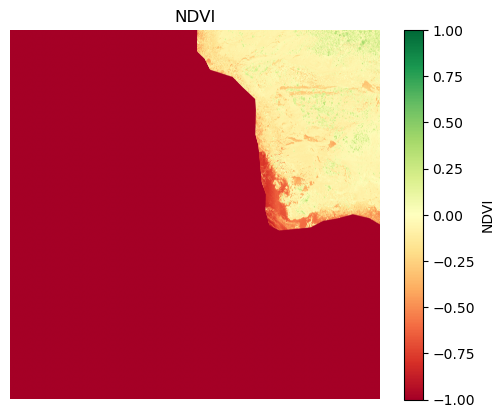

In [11]:
# view the computed NDVI using matplotlib to verify results
with rasterio.open(r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6376_1622c_norm_clip_ndvi.tif") as src:
    ndvi = src.read(1)

plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI")
plt.axis("off")
plt.show()

In [8]:
#Run the batch NDVI computation on all clipped TIF files
batch_compute_ndvi(
    input_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped",
    output_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI",
    red_band=3,
    nir_band=4
)

NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6434_1570b_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6434_1570c_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6434_1575a_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6440_1570b_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6434_1575b_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6445_1570b_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6440_1570c_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6434_1575c_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6376_1622c_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6445_1570c_norm_clip_ndvi.tif
NDVI saved: G:\473_588_Final_Project\LAR

In [ ]:
#forgot to copy associated files in the batch NDVI function, so adding that in now to maintain metadata and auxiliary files for the NDVI outputs

def batch_copy_associated_files(input_folder, output_folder):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)

    for input_tif in input_folder.rglob("*"):
        if input_tif.suffix.lower() in [".tif", ".tiff"]:
            relative_path = input_tif.relative_to(input_folder)

            output_tif = output_folder / relative_path
            output_tif = output_tif.with_name(f"{input_tif.stem}_ndvi.tif")

            if not output_tif.exists():
                print("Skipping, NDVI not found:", output_tif)
                continue

            copy_associated_files(input_tif, output_tif)

In [10]:
batch_copy_associated_files(
    input_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped",
    output_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI"
)

Copied: L7_6434_1570b_norm_clip.tfw
Copied: L7_6434_1570b_norm_clip.tif.aux.xml
Copied: L7_6434_1570c_norm_clip.tfw
Copied: L7_6434_1570c_norm_clip.tif.aux.xml
Copied: L7_6434_1575a_norm_clip.tfw
Copied: L7_6434_1575a_norm_clip.tif.aux.xml
Copied: L7_6440_1570b_norm_clip.tfw
Copied: L7_6440_1570b_norm_clip.tif.aux.xml
Copied: L7_6434_1575b_norm_clip.tfw
Copied: L7_6434_1575b_norm_clip.tif.aux.xml
Copied: L7_6445_1570b_norm_clip.tfw
Copied: L7_6445_1570b_norm_clip.tif.aux.xml
Copied: L7_6440_1570c_norm_clip.tfw
Copied: L7_6440_1570c_norm_clip.tif.aux.xml
Copied: L7_6434_1575c_norm_clip.tfw
Copied: L7_6434_1575c_norm_clip.tif.aux.xml
Copied: L7_6376_1622c_norm_clip.tfw
Copied: L7_6376_1622c_norm_clip.tif.aux.xml
Copied: L7_6445_1570c_norm_clip.tfw
Copied: L7_6445_1570c_norm_clip.tif.aux.xml
Copied: L7_6440_1575a_norm_clip.tfw
Copied: L7_6440_1575a_norm_clip.tif.aux.xml
Copied: L7_6455_1564b_norm_clip.tfw
Copied: L7_6455_1564b_norm_clip.tif.aux.xml
Copied: L7_6434_1575d_norm_clip.tfw
Copi

In [ ]:
tif_path = r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI\L7_6376_1622c_norm_clip_ndvi.tif"

with rasterio.open(tif_path) as src:
    print("CRS:", src.crs)
    
    # resolution (pixel size)
    res_x, res_y = src.res
    print("Resolution:", res_x, "x", res_y)
    
    # optional extras (useful for debugging alignment)
    print("Width x Height:", src.width, "x", src.height)
    print("Bounds:", src.bounds)

CRS: EPSG:6424
Resolution: 0.32 x 0.32
Width x Height: 8250 x 8250
Bounds: BoundingBox(left=6379360.0, bottom=1625520.0, right=6382000.0, top=1628160.0)


## Convert LARIAC RGBNIR to HSV

In [2]:
def rgb_to_hsv_tif(input_tif, output_tif, use_nir=False):
    input_tif = Path(input_tif)
    output_tif = Path(output_tif)
    output_tif.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(input_tif) as src:
        profile = src.profile.copy()
        nodata = src.nodata

        # --- READ BANDS ---
        if use_nir and src.count >= 4:
            # NAIP style: R,G,B,NIR
            n = src.read(4)
            r = src.read(1)
            g = src.read(2)

            rgb = np.dstack((n, r, g))  # pseudo RGB (NRG)
        else:
            r = src.read(1)
            g = src.read(2)
            b = src.read(3)

            rgb = np.dstack((r, g, b))

    # --- HANDLE NODATA ---
    rgb = rgb.astype("float32")

    if nodata is not None:
        nodata_mask = np.any(rgb == nodata, axis=2)
    else:
        nodata_mask = ~np.isfinite(rgb).all(axis=2)

    # set nodata pixels to 0 before conversion
    rgb[nodata_mask] = 0

    # ensure values stay in 0–1
    rgb = np.clip(rgb, 0, 1)

    # --- RGB → HSV ---
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    # restore nodata
    hsv[nodata_mask] = -9999

    # --- WRITE OUTPUT ---
    profile.update(
        count=3,
        dtype="float32",
        nodata=-9999,
        compress="lzw",
        BIGTIFF="YES"
    )

    with rasterio.open(output_tif, "w", **profile) as dst:
        dst.write(hsv[:, :, 0].astype("float32"), 1)  # H
        dst.write(hsv[:, :, 1].astype("float32"), 2)  # S
        dst.write(hsv[:, :, 2].astype("float32"), 3)  # V

    print("Saved HSV:", output_tif)

def batch_convert_to_hsv(input_folder, output_folder, image_type="rgb"):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    tif_files = list(input_folder.glob("*.tif")) + list(input_folder.glob("*.tiff"))

    print("Files found:", len(tif_files))

    for tif_file in tif_files:
        output_tif = output_folder / f"{tif_file.stem}_{image_type.lower()}_hsv.tif"

        if output_tif.exists():
            print("Skipping existing:", output_tif.name)
            continue

        print("Processing:", tif_file.name)

        try:
            if image_type.lower() == "rgb":
                rgb_to_hsv_tif(tif_file, output_tif, use_nir=False)

            elif image_type.lower() == "nrg":
                rgb_to_hsv_tif(tif_file, output_tif, use_nir=True)

            else:
                raise ValueError("image_type must be 'rgb' or 'nrg'")

        except Exception as e:
            print("Failed:", tif_file.name)
            print(e)

        gc.collect()

In [32]:
batch_convert_to_hsv(
    input_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped",
    output_folder=r"D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_HSV",
    image_type="rgb"
)

Files found: 368
Skipping existing: L7_6434_1570b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1570c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1575a_norm_clip_rgb_hsv.tif
Skipping existing: L7_6440_1570b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1575b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6445_1570b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6440_1570c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1575c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6376_1622c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6445_1570c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6440_1575a_norm_clip_rgb_hsv.tif
Skipping existing: L7_6455_1564b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1575d_norm_clip_rgb_hsv.tif
Skipping existing: L7_6445_1575a_norm_clip_rgb_hsv.tif
Skipping existing: L7_6440_1575b_norm_clip_rgb_hsv.tif
Skipping existing: L7_6455_1564c_norm_clip_rgb_hsv.tif
Skipping existing: L7_6434_1580a_norm_clip_rgb_hsv.tif
Skipping existing: L7_6376_1628a_norm_clip_rgb_h

In [33]:
batch_convert_to_hsv(
    input_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped",
    output_folder=r"D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV",
    image_type="nrg"
)

Files found: 368
Processing: L7_6434_1570b_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6434_1570b_norm_clip_nrg_hsv.tif
Processing: L7_6434_1570c_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6434_1570c_norm_clip_nrg_hsv.tif
Processing: L7_6434_1575a_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6434_1575a_norm_clip_nrg_hsv.tif
Processing: L7_6440_1570b_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6440_1570b_norm_clip_nrg_hsv.tif
Processing: L7_6434_1575b_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6434_1575b_norm_clip_nrg_hsv.tif
Processing: L7_6445_1570b_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV\L7_6445_1570b_norm_clip_nrg_hsv.tif
Processing: L7_6440_1570c_norm_clip.tif
Saved HSV: D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_

# LIDAR Data Processing

## 2025 LIDAR

### Normalize LIDAR data in R
- Create function to:
    - Set CRS to LARIAC CRS
    - Normalize height using a DTM
    - Filter by height (too short and too tall)
    - Remove Statistical outliers

In [2]:
def normalize_las_with_dtm(input_las, input_dtm, output_las):
    input_las = Path(input_las)
    input_dtm = Path(input_dtm)
    output_las = Path(output_las)

    output_las.parent.mkdir(parents=True, exist_ok=True)

    pipeline = {
        "pipeline": [
            {
                "type": "readers.las",
                "filename": str(input_las)
            },
            {
                "type": "filters.hag_dem",
                "raster": str(input_dtm)
            },
            {
                "type": "filters.ferry",
                "dimensions": "HeightAboveGround=>Z"
            },
            {
                "type": "filters.sample",
                "radius": 1.0
            },
            {
                "type": "filters.range",
                "limits": "Z[0:380)"
            },
            {
                "type": "filters.outlier",
                "method": "statistical",
                "mean_k": 16,
                "multiplier": 8
            },
            {
                "type": "filters.range",
                "limits": "Classification![7:7]"
            },
            {
                "type": "writers.las",
                "filename": str(output_las),
                "compression": "laszip"
            }
        ]
    }

    p = pdal.Pipeline(json.dumps(pipeline))
    p.execute()

    print("Saved:", output_las)

In [3]:
def normalize_las_catalog_with_dtm(input_folder, input_dtm, output_folder):
    input_folder = Path(input_folder)
    input_dtm = Path(input_dtm)
    output_folder = Path(output_folder)

    output_folder.mkdir(parents=True, exist_ok=True)

    lidar_files = list(input_folder.glob("*.las")) + list(input_folder.glob("*.laz"))

    print("Files found:", len(lidar_files))

    for lidar_file in lidar_files:
        output_file = output_folder / f"{lidar_file.stem}-dtm_Z_noise.laz"

        if output_file.exists():
            print("Skipping existing:", output_file.name)
            continue

        print("Processing:", lidar_file.name)

        try:
            normalize_las_with_dtm(
                input_las=lidar_file,
                input_dtm=input_dtm,
                output_las=output_file
            )

            gc.collect()
            time.sleep(2)

            print("Finished:", output_file.name)

        except Exception as e:
            print("Failed:", lidar_file.name)
            print(e)
            continue

In [4]:
normalize_las_catalog_with_dtm(
    input_folder=r'G:\473_588_Final_Project\NAIP\LIDAR_2025',
    input_dtm=r"D:\AAFinal_Project_cut_folders\Final_project_cut_folders\DEM_DSM\Catalina_DEM.tif",
    output_folder=r"G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR"
)

Files found: 265
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400.laz
Saved: G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise.laz
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300.laz
Saved: G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise.laz
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200.laz
Saved: G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise.laz
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100.laz
Saved: G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS0362

### Calculate Canopy Height
- Create function to:
    - create folder for canopy height models files
    - set crs to LARIAC crs (6424)
    - Use p2r algorithm to calculate CHM from LIDAR data
        - set desired pixel resolution
    - Use moving window to make a 'smoothed' CHM
    - Save as new raster file in CHM folder
- uses p95 (better for grasses)
- includes optional smoothing


In [9]:
def create_chm_from_las(input_las, output_tif, resolution=1.64042):
    pipeline = {
        "pipeline": [
            {
                "type": "readers.las",
                "filename": str(input_las),
                "override_srs": "EPSG:6340"
            },
            {
                "type": "filters.range",
                "limits": "Z[0:]"
            },
            {
                "type": "writers.gdal",
                "filename": str(output_tif),
                "resolution": resolution,
                "output_type": "p95",
                "binmode": True,
                "data_type": "float32",
                "nodata": -9999,
                "gdaldriver": "GTiff",
                "gdalopts": "COMPRESS=LZW"
            }
        ]
    }

    p = pdal.Pipeline(json.dumps(pipeline))
    p.execute()


def smooth_chm_median(input_tif, output_tif, size=3):
    with rasterio.open(input_tif) as src:
        data = src.read(1).astype("float32")
        profile = src.profile.copy()
        nodata = src.nodata

    if nodata is not None:
        data[data == nodata] = np.nan

    def nanmedian_filter(values):
        return np.nanmedian(values)

    smoothed = generic_filter(data, nanmedian_filter, size=size, mode="nearest")
    smoothed = smoothed.astype("float32")
    smoothed[np.isnan(smoothed)] = -9999

    profile.update(dtype="float32", nodata=-9999, compress="lzw")

    with rasterio.open(output_tif, "w", **profile) as dst:
        dst.write(smoothed, 1)


def batch_create_chm(input_folder, output_folder):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    las_files = list(input_folder.glob("*.las")) + list(input_folder.glob("*.laz"))

    print("Files found:", len(las_files))

    for las_file in las_files:
        raw_chm = output_folder / f"{las_file.stem}_raw_chm.tif"
        final_chm = output_folder / f"{las_file.stem}_chm_p95_05m.tif"

        if final_chm.exists():
            print("Skipping:", final_chm.name)
            continue

        print("Processing:", las_file.name)

        try:
            create_chm_from_las(
                input_las=las_file,
                output_tif=raw_chm,
                resolution=0.5
            )

            # optional smoothing (comment out if memory issues)
            smooth_chm_median(
                input_tif=raw_chm,
                output_tif=final_chm,
                size=3
            )

            # delete intermediate to save space
            if raw_chm.exists():
                raw_chm.unlink()

        except Exception as e:
            print("Failed:", las_file.name)
            print(e)

        gc.collect()

        print("Finished:", final_chm.name)

        if final_chm.exists():
            print("Finished:", final_chm.name)
        else:
            print("Did not create:", final_chm.name)

In [10]:
batch_create_chm(
    input_folder=r"G:\473_588_Final_Project\NAIP\Normalized_2025_LIDAR",
    output_folder=r"G:\473_588_Final_Project\NAIP\CHM_2025_LIDAR"
)

Files found: 265
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise.laz


C:\Users\Courtney\AppData\Local\Temp\ipykernel_11320\1154093694.py:41: RuntimeWarning: All-NaN slice encountered
  return np.nanmedian(values)


Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m.tif
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m.tif
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m.tif
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m.tif
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m.tif
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m.tif
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m.tif
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m.tif
Processing: USGS_LPC_CA_LosAngeles_B23_11SLS036200369000-dtm_Z_noise.laz
Finished: USGS_LPC_CA_LosAngeles_B23_11SLS03

In [10]:
tif_path = r"G:\473_588_Final_Project\NAIP\CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036100369900-dtm_Z_noise_chm_p95_05m.tif"

with rasterio.open(tif_path) as src:
    print("CRS:", src.crs)
    
    # resolution (pixel size)
    res_x, res_y = src.res
    print("Resolution:", res_x, "x", res_y)
    
    # optional extras (useful for debugging alignment)
    print("Width x Height:", src.width, "x", src.height)
    print("Bounds:", src.bounds)

CRS: EPSG:2229
Resolution: 1.64042 x 1.64042
Width x Height: 610 x 610
Bounds: BoundingBox(left=361000.0, bottom=3699000.0, right=362000.6562, top=3700000.6562)


### Reproject Canopy Height Model to 6424
- Create folder for reprojected CHM files
- Loop through all files in the CHM folder to set new CRS projection (6424)

In [11]:
def reproject_tif(input_tif, output_tif, dst_crs="EPSG:6424"):
    input_tif = Path(input_tif)
    output_tif = Path(output_tif)
    output_tif.parent.mkdir(parents=True, exist_ok=True)

    dst_nodata = -9999

    with rasterio.open(input_tif) as src:
        src_nodata = src.nodata if src.nodata is not None else dst_nodata

        transform, width, height = calculate_default_transform(
            src.crs,
            dst_crs,
            src.width,
            src.height,
            *src.bounds
        )

        profile = src.profile.copy()

        profile.update({
            "crs": dst_crs,
            "transform": transform,
            "width": width,
            "height": height,
            "dtype": "float32",
            "nodata": dst_nodata,
            "compress": "lzw",
            "BIGTIFF": "YES"
        })

        with rasterio.open(output_tif, "w", **profile) as dst:
            for band in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, band),
                    destination=rasterio.band(dst, band),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    src_nodata=src_nodata,
                    dst_transform=transform,
                    dst_crs=dst_crs,
                    dst_nodata=dst_nodata,
                    resampling=Resampling.bilinear
                )

    print("Saved:", output_tif)


def batch_reproject_chm(input_folder, output_folder, dst_crs="EPSG:6424"):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    tif_files = (
        list(input_folder.rglob("*.tif")) +
        list(input_folder.rglob("*.tiff"))
    )

    print("Files found:", len(tif_files))

    for tif in tif_files:
        relative_path = tif.relative_to(input_folder)

        output_tif = output_folder / relative_path
        output_tif = output_tif.with_name(f"{tif.stem}_epsg6424.tif")

        output_tif.parent.mkdir(parents=True, exist_ok=True)

        if output_tif.exists():
            print("Skipping existing:", output_tif.name)
            continue

        print("Reprojecting:", tif.name)

        try:
            reproject_tif(
                input_tif=tif,
                output_tif=output_tif,
                dst_crs=dst_crs
            )

        except Exception as e:
            print("Failed:", tif.name)
            print(e)

In [12]:
batch_reproject_chm(
    input_folder=r"G:\473_588_Final_Project\NAIP\CHM_2025_LIDAR",
    output_folder=r"G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR"
)

Files found: 265
Reprojecting: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m.tif
Saved: G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m_epsg6424.tif
Reprojecting: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m.tif
Saved: G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m_epsg6424.tif
Reprojecting: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m.tif
Saved: G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m_epsg6424.tif
Reprojecting: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m.tif
Saved: G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m_epsg6424.tif
Reprojecting: USGS_LPC_CA_LosAngeles_B23_11SLS036200369000-dtm_Z_noise_chm_

In [14]:
shp_path = r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\fin.shp"
tif_path = r"G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR\USGS_LPC_CA_LosAngeles_B23_11SLS035700369900-dtm_Z_noise_chm_p95_05m_epsg6424.tif"

# Read shapefile
shape = gpd.read_file(shp_path)

# Read raster info
with rasterio.open(tif_path) as src:
    raster_crs = src.crs
    raster_bounds = src.bounds
    raster_box = box(*raster_bounds)

print("Shapefile CRS:")
print(shape.crs)

print("\nRaster CRS:")
print(raster_crs)

print("\nShapefile bounds:")
print(shape.total_bounds)

print("\nRaster bounds:")
print(raster_bounds)

# Reproject shapefile to raster CRS
shape_proj = shape.to_crs(raster_crs)

print("\nReprojected shapefile bounds:")
print(shape_proj.total_bounds)

# Check overlap
shape_box = box(*shape_proj.total_bounds)

print("\nDo they overlap?")
print(shape_box.intersects(raster_box))

Shapefile CRS:
EPSG:6424

Raster CRS:
EPSG:6424

Shapefile bounds:
[6376730.60791028 1567510.54858717 6468937.67938726 1633405.13285327]

Raster bounds:
BoundingBox(left=6397478.075939402, bottom=1614254.5630795462, right=6400714.063533655, top=1615358.934099289)

Reprojected shapefile bounds:
[6376730.60791028 1567510.54858717 6468937.67938726 1633405.13285327]

Do they overlap?
True


### Clip CHM to WMU Shapefile

In [15]:

def clip_tif_with_shp_skip_no_overlap(input_tif, input_shp, output_tif):
    input_tif = Path(input_tif)
    output_tif = Path(output_tif)

    gdf = gpd.read_file(input_shp)

    with rasterio.open(input_tif) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)

        gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

        raster_box = box(*src.bounds)
        gdf_overlap = gdf[gdf.intersects(raster_box)]

        if gdf_overlap.empty:
            print("Skipping, no overlap:", input_tif.name)
            return

        out_image, out_transform = mask(
            src,
            list(gdf_overlap.geometry),
            crop=True,
            nodata=-9999
        )

        out_meta = src.meta.copy()
        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
            "nodata": -9999,
            "compress": "lzw",
            "BIGTIFF": "YES"
        })

    output_tif.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(output_tif, "w", **out_meta) as dst:
        dst.write(out_image)

    print("Saved:", output_tif)


def batch_clip_chm(input_folder, output_folder, input_shp):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)

    for tif in input_folder.rglob("*.tif"):
        output_tif = output_folder / f"{tif.stem}_clip.tif"

        if output_tif.exists():
            print("Skipping existing:", output_tif.name)
            continue

        clip_tif_with_shp_skip_no_overlap(
            input_tif=tif,
            input_shp=input_shp,
            output_tif=output_tif
        )

In [16]:
batch_clip_chm(
    input_folder=r"G:\473_588_Final_Project\NAIP\Repro_CHM_2025_LIDAR",
    output_folder=r"G:\473_588_Final_Project\NAIP\CHM_Clipped_2025",
    input_shp=r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\fin.shp"
)

Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200369000-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036200368900-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Skipping, no overlap: USGS_LPC_CA_LosAngeles_B23_11SLS036200368800-dtm_Z_noise_chm_p95_05m_epsg6424.tif
Saved: G:\473_588_Final_Project\NAIP\CHM_Clipped_2

### Mosaic 2025 CHM so it can be stacked with all other data.

In [ ]:
def mosaic_tifs(input_folder, output_tif):
    input_folder = Path(input_folder)
    output_tif = Path(output_tif)

    tif_files = (
        list(input_folder.rglob("*.tif")) +
        list(input_folder.rglob("*.tiff"))
    )

    print("Files found:", len(tif_files))

    if len(tif_files) == 0:
        print("No tif files found")
        return

    src_files = []

    try:
        for tif in tif_files:
            print("Opening:", tif.name)
            src = rasterio.open(tif)
            src_files.append(src)

        mosaic, transform = merge(
            src_files,
            nodata=-9999
        )

        profile = src_files[0].profile.copy()

        profile.update(
            height=mosaic.shape[1],
            width=mosaic.shape[2],
            transform=transform,
            count=mosaic.shape[0],
            dtype="float32",
            nodata=-9999,
            compress="lzw",
            BIGTIFF="YES",
            tiled=True,
            blockxsize=256,
            blockysize=256
        )

        with rasterio.open(output_tif, "w", **profile) as dst:
            dst.write(mosaic.astype("float32"))

        print("Saved mosaic:", output_tif)

    finally:
        for src in src_files:
            src.close()

        gc.collect()

In [ ]:
mosaic_tifs(
    input_folder=r"G:\473_588_Final_Project\NAIP\CHM_Clipped_2025",
    output_tif=r"G:\473_588_Final_Project\NAIP\2025_chm_mosaic.tif"
)

Files found: 249
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200369400-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200369300-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200369200-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200369100-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200369000-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036200368900-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036100369900-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036100369800-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036100369600-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_LosAngeles_B23_11SLS036100369300-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif
Opening: USGS_LPC_CA_Lo

## Make Slope and Aspect Layers

### Clip DEM/DTM for Slope and Aspect Creation

In [2]:
def clip_tif_with_shp_gdal(
    input_tif,
    input_shp,
    output_tif,
    nodata=-9999
):
    input_tif = str(input_tif)
    input_shp = str(input_shp)
    output_tif = str(output_tif)

    Path(output_tif).parent.mkdir(parents=True, exist_ok=True)

    gdal.Warp(
        destNameOrDestDS=output_tif,
        srcDSOrSrcDSTab=input_tif,
        cutlineDSName=input_shp,
        cropToCutline=True,
        dstNodata=nodata,
        multithread=True,
        creationOptions=[
            "COMPRESS=LZW",
            "TILED=YES",
            "BIGTIFF=YES"
        ]
    )

    print("Saved clipped raster:")
    print(output_tif)

In [3]:
# pysheds for making slope and aspect

clip_tif_with_shp_gdal(
    input_tif=r"E:\Final_project_cut_folders\DEM_DSM\DTM_epsg6340.tif", 
    input_shp=r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\fin.shp", 
    output_tif=r'D:\AAFinal_Project_cut_folders\DTM_epsg6340_clip.tif')

e:\Anaconda\envs\lidar\Lib\site-packages\osgeo\gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Saved clipped raster:
D:\AAFinal_Project_cut_folders\DTM_epsg6340_clip.tif


### Slope and Aspect Creation

In [4]:
def create_slope_aspect_from_dtm(input_dtm, output_slope, output_aspect):
    input_dtm = Path(input_dtm)
    output_slope = Path(output_slope)
    output_aspect = Path(output_aspect)

    output_slope.parent.mkdir(parents=True, exist_ok=True)
    output_aspect.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(input_dtm) as src:
        profile = src.profile.copy()
        nodata = src.nodata

        xres = abs(src.transform.a)
        yres = abs(src.transform.e)

        profile.update(
            dtype="float32",
            count=1,
            nodata=-9999,
            compress="lzw",
            BIGTIFF="YES",
            tiled=True
        )

        with rasterio.open(output_slope, "w", **profile) as slope_dst, \
             rasterio.open(output_aspect, "w", **profile) as aspect_dst:

            for _, window in src.block_windows(1):
                print("Processing window:", window)

                # add 1-cell border around each block for gradient calculation
                read_window = Window(
                    window.col_off - 1,
                    window.row_off - 1,
                    window.width + 2,
                    window.height + 2
                )

                data = src.read(
                    1,
                    window=read_window,
                    boundless=True,
                    fill_value=nodata if nodata is not None else -9999
                ).astype("float32")

                if nodata is not None:
                    data[data == nodata] = np.nan
                data[data == -9999] = np.nan

                # dz/dy and dz/dx
                dzdy, dzdx = np.gradient(data, yres, xres)

                # slope in degrees
                slope = np.degrees(np.arctan(np.sqrt(dzdx**2 + dzdy**2)))

                # aspect in degrees, GIS style
                aspect = np.degrees(np.arctan2(dzdy, -dzdx))
                aspect = 90.0 - aspect
                aspect[aspect < 0] += 360.0
                aspect[aspect >= 360] -= 360.0

                # flat areas get aspect -1
                flat = slope == 0
                aspect[flat] = -1

                # remove halo so output matches original block
                slope_out = slope[1:1 + int(window.height), 1:1 + int(window.width)]
                aspect_out = aspect[1:1 + int(window.height), 1:1 + int(window.width)]

                slope_out = slope_out.astype("float32")
                aspect_out = aspect_out.astype("float32")

                slope_out[~np.isfinite(slope_out)] = -9999
                aspect_out[~np.isfinite(aspect_out)] = -9999

                slope_dst.write(slope_out, 1, window=window)
                aspect_dst.write(aspect_out, 1, window=window)

    print("Saved slope:", output_slope)
    print("Saved aspect:", output_aspect)

In [5]:
create_slope_aspect_from_dtm(
    input_dtm=r'D:\AAFinal_Project_cut_folders\DTM_epsg6340_clip.tif',
    output_slope=r'D:\AAFinal_Project_cut_folders\DTM_slope.tif',
    output_aspect=r'D:\AAFinal_Project_cut_folders\DTM_aspect.tif'
)

Processing window: Window(col_off=0, row_off=0, width=256, height=256)
Processing window: Window(col_off=256, row_off=0, width=256, height=256)
Processing window: Window(col_off=512, row_off=0, width=256, height=256)
Processing window: Window(col_off=768, row_off=0, width=256, height=256)
Processing window: Window(col_off=1024, row_off=0, width=256, height=256)
Processing window: Window(col_off=1280, row_off=0, width=256, height=256)
Processing window: Window(col_off=1536, row_off=0, width=256, height=256)
Processing window: Window(col_off=1792, row_off=0, width=256, height=256)
Processing window: Window(col_off=2048, row_off=0, width=256, height=256)
Processing window: Window(col_off=2304, row_off=0, width=256, height=256)
Processing window: Window(col_off=2560, row_off=0, width=256, height=256)
Processing window: Window(col_off=2816, row_off=0, width=256, height=256)
Processing window: Window(col_off=3072, row_off=0, width=256, height=256)
Processing window: Window(col_off=3328, row_

# Stack all the things

In [2]:
def get_raster_bounds_info(raster_path):
    raster_path = Path(raster_path)

    with rasterio.open(raster_path) as src:
        bounds_geom = box(*src.bounds)

        return {
            "path": raster_path,
            "bounds": bounds_geom,
            "crs": src.crs,
            "width": src.width,
            "height": src.height,
            "count": src.count
        }


def build_raster_index(folder):
    folder = Path(folder)

    files = sorted(
        list(folder.rglob("*.tif")) +
        list(folder.rglob("*.tiff"))
    )

    index = []

    for file in files:
        try:
            info = get_raster_bounds_info(file)
            index.append(info)
        except Exception as e:
            print("Could not read:", file)
            print(e)

    print("Indexed", len(index), "rasters from", folder)

    return index


def find_best_overlap(reference_raster, raster_index):
    ref_info = get_raster_bounds_info(reference_raster)
    ref_bounds = ref_info["bounds"]

    best_file = None
    best_area = 0

    for item in raster_index:
        candidate_bounds = item["bounds"]

        if not ref_bounds.intersects(candidate_bounds):
            continue

        intersection_area = ref_bounds.intersection(candidate_bounds).area

        if intersection_area > best_area:
            best_area = intersection_area
            best_file = item["path"]

    return best_file


def generate_windows(width, height, window_size=8192):
    for row_start in range(0, height, window_size):
        for col_start in range(0, width, window_size):
            win_width = min(window_size, width - col_start)
            win_height = min(window_size, height - row_start)

            yield Window(
                col_off=col_start,
                row_off=row_start,
                width=win_width,
                height=win_height
            )


def align_raster_band_to_reference_window(
    input_raster,
    reference_src,
    window,
    band_number=1,
    nodata_value=-9999,
    resampling_method="nearest"
):
    if resampling_method == "bilinear":
        resampling = Resampling.bilinear
    else:
        resampling = Resampling.nearest

    destination = np.full(
        (int(window.height), int(window.width)),
        nodata_value,
        dtype="float32"
    )

    dst_transform = reference_src.window_transform(window)

    with rasterio.open(input_raster) as src:
        reproject(
            source=rasterio.band(src, band_number),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=dst_transform,
            dst_crs=reference_src.crs,
            dst_nodata=nodata_value,
            resampling=resampling
        )

    destination[~np.isfinite(destination)] = nodata_value

    return destination


def build_valid_mask_15band_window(stack_window, nodata_value=-9999):
    stack_window = stack_window.astype("float32")
    stack_window[stack_window == nodata_value] = np.nan

    ndvi = stack_window[4]
    chm2025 = stack_window[14]

    valid = (
        np.all(np.isfinite(stack_window), axis=0) &
        (ndvi >= -1) &
        (ndvi <= 1) &
        (chm2025 >= 0)
    )

    return valid


def batch_build_15band_stacks_by_spatial_overlap(
    reference_ndvi_folder,
    output_folder,

    rgb_nir_folder,
    rgb_hsv_folder,
    nrg_hsv_folder,

    dtm_raster,
    slope_raster,
    aspect_raster,
    chm2025_raster,

    nodata_value=-9999,
    window_size=8192
):
    reference_ndvi_folder = Path(reference_ndvi_folder)
    output_folder = Path(output_folder)

    output_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    reference_tiles = sorted(
        list(reference_ndvi_folder.rglob("*.tif")) +
        list(reference_ndvi_folder.rglob("*.tiff"))
    )

    print("Reference NDVI tiles:")
    print(len(reference_tiles))

    layer_indexes = {
        "rgb_nir": build_raster_index(rgb_nir_folder),
        "rgb_hsv": build_raster_index(rgb_hsv_folder),
        "nrg_hsv": build_raster_index(nrg_hsv_folder)
    }

    for reference_ndvi in reference_tiles:

        print("\nProcessing:")
        print(reference_ndvi.name)

        output_raster = (
            output_folder /
            f"{reference_ndvi.stem}_15band_stack.tif"
        )

        if output_raster.exists():
            print("Already exists, skipping")
            continue

        matched = {}
        missing_layer = False

        for layer_name in layer_indexes:
            match = find_best_overlap(
                reference_ndvi,
                layer_indexes[layer_name]
            )

            if match is None:
                print("Missing overlap:")
                print(layer_name)
                missing_layer = True
                break

            matched[layer_name] = match

        if missing_layer:
            print("Skipping tile")
            continue

        try:
            print("Matched files:")

            for key, value in matched.items():
                print(key, ":", value.name)

            with rasterio.open(reference_ndvi) as ref_src:

                profile = ref_src.profile.copy()

                profile.update({
                    "count": 15,
                    "dtype": "float32",
                    "nodata": nodata_value,
                    "BIGTIFF": "YES"
                })

                with rasterio.open(output_raster, "w", **profile) as dst:

                    for window in generate_windows(
                        ref_src.width,
                        ref_src.height,
                        window_size=window_size
                    ):

                        stack_window = np.full(
                            (
                                15,
                                int(window.height),
                                int(window.width)
                            ),
                            nodata_value,
                            dtype="float32"
                        )

                        # bands 1-4: blue, green, red, nir
                        for src_band, stack_index in [
                            (1, 0),
                            (2, 1),
                            (3, 2),
                            (4, 3)
                        ]:
                            stack_window[stack_index] = (
                                align_raster_band_to_reference_window(
                                    input_raster=matched["rgb_nir"],
                                    reference_src=ref_src,
                                    window=window,
                                    band_number=src_band,
                                    nodata_value=nodata_value,
                                    resampling_method="nearest"
                                )
                            )

                        # band 5: ndvi
                        ndvi = ref_src.read(
                            1,
                            window=window,
                            out_dtype="float32"
                        )

                        ndvi[~np.isfinite(ndvi)] = nodata_value
                        stack_window[4] = ndvi

                        # bands 6-8: rgb hsv
                        for src_band, stack_index in [
                            (1, 5),
                            (2, 6),
                            (3, 7)
                        ]:
                            stack_window[stack_index] = (
                                align_raster_band_to_reference_window(
                                    input_raster=matched["rgb_hsv"],
                                    reference_src=ref_src,
                                    window=window,
                                    band_number=src_band,
                                    nodata_value=nodata_value,
                                    resampling_method="nearest"
                                )
                            )

                        # bands 9-11: nrg hsv
                        for src_band, stack_index in [
                            (1, 8),
                            (2, 9),
                            (3, 10)
                        ]:
                            stack_window[stack_index] = (
                                align_raster_band_to_reference_window(
                                    input_raster=matched["nrg_hsv"],
                                    reference_src=ref_src,
                                    window=window,
                                    band_number=src_band,
                                    nodata_value=nodata_value,
                                    resampling_method="nearest"
                                )
                            )

                        # bands 12-15: dtm, slope, aspect, chm2025
                        for input_raster, stack_index in [
                            (dtm_raster, 11),
                            (slope_raster, 12),
                            (aspect_raster, 13),
                            (chm2025_raster, 14)
                        ]:
                            stack_window[stack_index] = (
                                align_raster_band_to_reference_window(
                                    input_raster=input_raster,
                                    reference_src=ref_src,
                                    window=window,
                                    band_number=1,
                                    nodata_value=nodata_value,
                                    resampling_method="nearest"
                                )
                            )

                        valid_mask = build_valid_mask_15band_window(
                            stack_window,
                            nodata_value=nodata_value
                        )

                        stack_window[:, ~valid_mask] = nodata_value

                        dst.write(
                            stack_window,
                            window=window
                        )

                        del stack_window

            print("Saved:")
            print(output_raster)

        except Exception as e:
            print("Error processing:")
            print(reference_ndvi.name)
            print(e)

        finally:
            gc.collect()

In [4]:
with rasterio.Env(
    GDAL_NUM_THREADS="ALL_CPUS",
    NUM_THREADS="ALL_CPUS",
    GDAL_CACHEMAX=4096
):
    batch_build_15band_stacks_by_spatial_overlap(
        reference_ndvi_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_NDVI",
        output_folder=r"E:\AAFinal_Project_cut_folders\Full_15_Band_Stacks",

        rgb_nir_folder=r"G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped",
        
        rgb_hsv_folder=r"D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_HSV",
        nrg_hsv_folder=r"D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV",

        dtm_raster=r"D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif",
        slope_raster=r"D:\AAFinal_Project_cut_folders\DTM_slope.tif",
        aspect_raster=r"D:\AAFinal_Project_cut_folders\DTM_aspect.tif",
        chm2025_raster=r"G:\473_588_Final_Project\NAIP\2025_chm_mosaic.tif"
    )

Reference NDVI tiles:
368
Indexed 368 rasters from G:\473_588_Final_Project\LARIAC_Data\LARIAC_7_Clipped
Indexed 368 rasters from D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_HSV
Indexed 368 rasters from D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_NRG_HSV

Processing:
L7_6376_1622c_norm_clip_ndvi.tif
Matched files:
rgb_nir : L7_6376_1622c_norm_clip.tif
rgb_hsv : L7_6376_1622c_norm_clip_rgb_hsv.tif
nrg_hsv : L7_6376_1622c_norm_clip_nrg_hsv.tif
Saved:
E:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1622c_norm_clip_ndvi_15band_stack.tif

Processing:
L7_6376_1628a_norm_clip_ndvi.tif
Matched files:
rgb_nir : L7_6376_1628a_norm_clip.tif
rgb_hsv : L7_6376_1628a_norm_clip_rgb_hsv.tif
nrg_hsv : L7_6376_1628a_norm_clip_nrg_hsv.tif
Saved:
E:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1628a_norm_clip_ndvi_15band_stack.tif

Processing:
L7_6376_1628b_norm_clip_ndvi.tif
Matched files:
rgb_nir : L7_6376_1628b_norm_clip.tif
rgb_hsv : L7_6376_1628b_norm_clip_rgb_hs

### Sanity check: CRS, resolution and extent check

In [17]:
def inspect_geodata(paths):
    paths = [Path(p) for p in paths]

    for p in paths:
        print("\n---", p.name, "---")

        try:
            # --- RASTER ---
            if p.suffix.lower() in [".tif", ".tiff"]:
                with rasterio.open(p) as src:
                    print("Type: Raster")
                    print("CRS:", src.crs)
                    print("Bounds:", src.bounds)
                    print("Resolution:", src.res)
                    print("Shape (rows, cols):", (src.height, src.width))
                    print("Band count:", src.count)
                    print("Nodata:", src.nodata)

            # --- VECTOR ---
            elif p.suffix.lower() in [".shp", ".geojson"]:
                gdf = gpd.read_file(p)

                print("Type: Vector")
                print("CRS:", gdf.crs)
                print("Bounds:", gdf.total_bounds)
                print("Feature count:", len(gdf))

            else:
                print("Unsupported file type")

        except Exception as e:
            print("Error reading file:", e)

In [18]:
inspect_geodata([
    # 6 band stack
    r"G:\473_588_Final_Project\NAIP\CHM_NDVI_4BAND_2016_L7\USGS_LPC_CA_LosAngeles_2016_L4_6376_1622c_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band.tif",
    # HSV converted LARIAC Images
    r"D:\AAFinal_Project_cut_folders\LARIAC_Data\LARIAC_7_HSV\L7_6376_1628d_norm_clip_rgb_hsv.tif",
    # DEM
    r"D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif",
    # Training Data
    r"G:\473_588_Final_Project\shapes\species_cleaned\F_vulgare_cleaned_buffered.shp",
    # LIDAR 2025
    r'G:\473_588_Final_Project\NAIP\CHM_Clipped_2025\USGS_LPC_CA_LosAngeles_B23_11SLS036300369000-dtm_Z_noise_chm_p95_05m_epsg6424_clip.tif'
    
])


--- USGS_LPC_CA_LosAngeles_2016_L4_6376_1622c_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band.tif ---
Type: Raster
CRS: EPSG:6424
Bounds: BoundingBox(left=6379360.0, bottom=1625520.0, right=6382000.0, top=1628160.0)
Resolution: (0.32, 0.32)
Shape (rows, cols): (8250, 8250)
Band count: 6
Nodata: -9999.0

--- L7_6376_1628d_norm_clip_rgb_hsv.tif ---
Type: Raster
CRS: EPSG:6424
Bounds: BoundingBox(left=6379360.0, bottom=1628160.0, right=6382000.0, top=1630800.0)
Resolution: (0.32, 0.32)
Shape (rows, cols): (8250, 8250)
Band count: 3
Nodata: -9999.0

--- DTM_epsg6424.tif ---
Type: Raster
CRS: EPSG:6424
Bounds: BoundingBox(left=6376730.547664503, bottom=1566711.591108805, right=6469008.082448007, top=1634272.9826528332)
Resolution: (1.0000057954149304, 1.0000057954149304)
Shape (rows, cols): (67561, 92277)
Band count: 1
Nodata: -9999.0

--- F_vulgare_cleaned_buffered.shp ---
Type: Vector
CRS: EPSG:6424
Bounds: [6386704.60097127 1582201.7519336  6463309

Current CRS's: 

- 6 Band Stack
    -EPSG: 6424
- HSV LARIAC
    - EPSG: 6424
- DEM/DTM
    - EPSG: 2229
- Training Data
    - Background: EPSG: 2229
    - Species: EPSG: 6424
- LIDAR 2025
    - EPSG: 6424
- K-Means Clustering
    - EPSG:6424

### Convert CRS's as needed

In [13]:
#### Reproject DTM

def reproject_dtm_to_epsg6424(input_dtm, output_dtm):
    input_dtm = Path(input_dtm)
    output_dtm = Path(output_dtm)

    output_dtm.parent.mkdir(parents=True, exist_ok=True)

    dst_crs = "EPSG:6424"

    with rasterio.open(input_dtm) as src:
        transform, width, height = calculate_default_transform(
            src.crs,
            dst_crs,
            src.width,
            src.height,
            *src.bounds
        )

        kwargs = src.meta.copy()
        kwargs.update({
            "crs": dst_crs,
            "transform": transform,
            "width": width,
            "height": height,
            "compress": "lzw",
            "BIGTIFF": "YES"
})

        with rasterio.open(output_dtm, "w", **kwargs) as dst:
            for band in range(1, src.count + 1):
                reproject(
                    source=rasterio.band(src, band),
                    destination=rasterio.band(dst, band),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=dst_crs,
                    resampling=Resampling.bilinear
                )

    print("Saved reprojected DTM:", output_dtm)

reproject_dtm_to_epsg6424(
    input_dtm=r"D:\AAFinal_Project_cut_folders\DTM_epsg6340_clip.tif",
    output_dtm=r"D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif"
)


Saved reprojected DTM: D:\AAFinal_Project_cut_folders\DTM_epsg6424.tif


Reproject Shape Files

In [14]:
# Input shapefile
input_shp = r"G:\473_588_Final_Project\shapes\drawn_background.shp"

# Output shapefile
output_shp = r"G:\473_588_Final_Project\shapes\species_cleaned\background_epsg6424.shp"

# Read shapefile
gdf = gpd.read_file(input_shp)

# Check original CRS
print("Original CRS:", gdf.crs)

# Reproject to EPSG:6424
gdf_reprojected = gdf.to_crs(epsg=6424)

# Save new shapefile
gdf_reprojected.to_file(output_shp)

print("Finished reprojection.")
print("New CRS:", gdf_reprojected.crs)

Original CRS: EPSG:8718
Finished reprojection.
New CRS: EPSG:6424


## Verify Band Order

## Clean Training Data

Standardize dates and remove anything older than 2023 year data from G. lenifolia

In [20]:

def clean_species_shapefile_with_buffers(
    input_shp,
    output_shp,
    date_column,
    standardized_date_column="survey_date",
    start_date=None,
    end_date=None,
    point_buffer=5,
    line_buffer=5
):
    """
    Cleans one species shapefile.

    What it does:
    - Standardizes date column
    - Optionally filters by date
    - Converts points and lines into polygons using buffers
    - Keeps existing polygons
    - Saves cleaned shapefile

    Buffer distance uses the shapefile CRS units.
    If CRS is EPSG:6424, buffer values are feet.
    """

    input_shp = Path(input_shp)
    output_shp = Path(output_shp)
    output_shp.parent.mkdir(parents=True, exist_ok=True)

    gdf = gpd.read_file(input_shp)

    print("\nProcessing:", input_shp.name)
    print("Original rows:", len(gdf))
    print("Original geometry types:")
    print(gdf.geometry.geom_type.value_counts())

    gdf[standardized_date_column] = pd.to_datetime(
        gdf[date_column],
        errors="coerce"
    )

    gdf = gdf[gdf[standardized_date_column].notna()].copy()

    if start_date is not None:
        gdf = gdf[gdf[standardized_date_column] >= pd.to_datetime(start_date)]

    if end_date is not None:
        gdf = gdf[gdf[standardized_date_column] <= pd.to_datetime(end_date)]

    gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty].copy()

    def convert_to_polygon(geom):
        geom_type = geom.geom_type

        if geom_type in ["Polygon", "MultiPolygon"]:
            return geom

        if geom_type in ["Point", "MultiPoint"]:
            return geom.buffer(point_buffer)

        if geom_type in ["LineString", "MultiLineString"]:
            return geom.buffer(line_buffer)

        return None

    gdf["geometry"] = gdf.geometry.apply(convert_to_polygon)

    gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty].copy()

    gdf = gdf[
        gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
    ].copy()

    print("Cleaned rows:", len(gdf))
    print("Cleaned geometry types:")
    print(gdf.geometry.geom_type.value_counts())

    gdf[standardized_date_column] = gdf[standardized_date_column].dt.strftime("%Y-%m-%d")

    gdf.to_file(output_shp)

    print("Saved:", output_shp)

In [21]:
def batch_clean_species_shapefiles_with_buffers(
    species_files,
    output_folder,
    date_column,
    start_date=None,
    end_date=None,
    point_buffer=5,
    line_buffer=5
):
    output_folder = Path(output_folder)

    for shp in species_files:
        shp = Path(shp)
        output_shp = output_folder / f"{shp.stem}_cleaned_buffered.shp"

        clean_species_shapefile_with_buffers(
            input_shp=shp,
            output_shp=output_shp,
            date_column=date_column,
            start_date=start_date,
            end_date=end_date,
            point_buffer=point_buffer,
            line_buffer=line_buffer
        )

In [22]:

batch_clean_species_shapefiles_with_buffers(
    species_files=[
        r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\epsg_6424\F_vulgare.shp",
        r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\epsg_6424\G_linifolia.shp",
        r"G:\473_588_Final_Project\Catalina_LARIAC_Background_files\Shapefiles\epsg_6424\P_aquatica.shp"
    ],
    output_folder=r"G:/473_588_Final_Project/shapes/species_cleaned",
    date_column="Surveydate",
    start_date="2023-01-01",
    end_date="2025-12-31",
    point_buffer=5,
    line_buffer=5
)


Processing: F_vulgare.shp
Original rows: 273
Original geometry types:
Polygon         263
MultiPolygon     10
Name: count, dtype: int64
Cleaned rows: 214
Cleaned geometry types:
Polygon         209
MultiPolygon      5
Name: count, dtype: int64


C:\Users\Courtney\AppData\Local\Temp\ipykernel_14420\283578663.py:79: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(output_shp)


Saved: G:\473_588_Final_Project\shapes\species_cleaned\F_vulgare_cleaned_buffered.shp

Processing: G_linifolia.shp
Original rows: 830
Original geometry types:
Polygon         819
MultiPolygon     11
Name: count, dtype: int64
Cleaned rows: 591
Cleaned geometry types:
Polygon         581
MultiPolygon     10
Name: count, dtype: int64
Saved: G:\473_588_Final_Project\shapes\species_cleaned\G_linifolia_cleaned_buffered.shp


C:\Users\Courtney\AppData\Local\Temp\ipykernel_14420\283578663.py:79: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(output_shp)



Processing: P_aquatica.shp
Original rows: 218
Original geometry types:
Polygon         211
MultiPolygon      7
Name: count, dtype: int64
Cleaned rows: 101
Cleaned geometry types:
Polygon         100
MultiPolygon      1
Name: count, dtype: int64
Saved: G:\473_588_Final_Project\shapes\species_cleaned\P_aquatica_cleaned_buffered.shp


C:\Users\Courtney\AppData\Local\Temp\ipykernel_14420\283578663.py:79: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(output_shp)


# Machine Learning: CART and K-means Clustering

### K-means Clustering

Used minibatchkmeans because the data set was too big.

In [11]:

os.environ["OMP_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"] = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["NUMEXPR_NUM_THREADS"] = "8"




def batch_minibatch_kmeans_16band_stacks(
    input_folder,
    output_folder,
    n_clusters=6,
    batch_size=80000
):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    tif_files = sorted(
        list(input_folder.rglob("*.tif")) +
        list(input_folder.rglob("*.tiff"))
    )

    print("Files found:", len(tif_files))

    for tif in tif_files:
        output_tif = output_folder / f"{tif.stem}_minibatch_kmeans_{n_clusters}class.tif"

        print("\nProcessing:", tif.name)

        try:
            with rasterio.open(tif) as src:
                print("Band count:", src.count)

                if src.count != 15:
                    print("Skipping, expected 15 bands")
                    continue

                stack = src.read().astype("float32")
                profile = src.profile.copy()
                nodata = src.nodata

            bands, rows, cols = stack.shape

            if nodata is not None:
                stack[stack == nodata] = np.nan

            X = stack.reshape(bands, rows * cols).T

            valid_mask = np.all(np.isfinite(X), axis=1)
            X_valid = X[valid_mask]

            print("Total pixels:", rows * cols)
            print("Valid pixels:", X_valid.shape[0])

            if X_valid.shape[0] == 0:
                print("Skipping, no valid pixels")
                continue

            kmeans = MiniBatchKMeans(
                n_clusters=n_clusters,
                random_state=42,
                batch_size=batch_size,
                n_init=3
            )

            labels = kmeans.fit_predict(X_valid)

            classified = np.full(rows * cols, -9999, dtype="int16")
            classified[valid_mask] = labels + 1
            classified = classified.reshape(rows, cols)

            profile.update(
                count=1,
                dtype="int16",
                nodata=-9999,
                compress="lzw",
                BIGTIFF="YES"
            )

            with rasterio.open(output_tif, "w", **profile) as dst:
                dst.write(classified, 1)

            print("Saved:", output_tif)

        except Exception as e:
            print("Error processing:", tif.name)
            print(e)

        finally:
            gc.collect()

In [12]:
with rasterio.Env(
    GDAL_NUM_THREADS="ALL_CPUS",
    NUM_THREADS="ALL_CPUS",
    GDAL_CACHEMAX=8192
):

    batch_minibatch_kmeans_16band_stacks(
        input_folder=r"D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks",
        output_folder=r"G:\473_588_Final_Project\ML\KMeans_15Band",
        n_clusters=6,
        batch_size=80000
    )

Files found: 368

Processing: L7_6376_1622c_norm_clip_ndvi_15band_stack.tif
Band count: 15
Total pixels: 68062500
Valid pixels: 12566708


e:\Anaconda\envs\lidar\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Saved: G:\473_588_Final_Project\ML\KMeans_15Band\L7_6376_1622c_norm_clip_ndvi_15band_stack_minibatch_kmeans_6class.tif

Processing: L7_6376_1628a_norm_clip_ndvi_15band_stack.tif
Band count: 15
Total pixels: 67930500
Valid pixels: 13184366
Saved: G:\473_588_Final_Project\ML\KMeans_15Band\L7_6376_1628a_norm_clip_ndvi_15band_stack_minibatch_kmeans_6class.tif

Processing: L7_6376_1628b_norm_clip_ndvi_15band_stack.tif
Band count: 15
Total pixels: 67107100
Valid pixels: 35691404
Saved: G:\473_588_Final_Project\ML\KMeans_15Band\L7_6376_1628b_norm_clip_ndvi_15band_stack_minibatch_kmeans_6class.tif

Processing: L7_6376_1628c_norm_clip_ndvi_15band_stack.tif
Band count: 15
Total pixels: 67237500
Valid pixels: 35632301
Saved: G:\473_588_Final_Project\ML\KMeans_15Band\L7_6376_1628c_norm_clip_ndvi_15band_stack_minibatch_kmeans_6class.tif

Processing: L7_6376_1628d_norm_clip_ndvi_15band_stack.tif
Band count: 15
Total pixels: 68062500
Valid pixels: 51922861
Saved: G:\473_588_Final_Project\ML\KMeans_15

#### Regular K-Means Clustering if your computer can handle it.

In [37]:
def run_kmeans_16band_stack(input_stack, output_tif, n_clusters=5):
    input_stack = Path(input_stack)
    output_tif = Path(output_tif)
    output_tif.parent.mkdir(parents=True, exist_ok=True)

    with rasterio.open(input_stack) as src:
        print("Opening:", input_stack.name)
        print("Band count:", src.count)

        if src.count != 16:
            print("Warning: expected 16 bands, found", src.count)

        stack = src.read().astype("float32")
        profile = src.profile.copy()
        nodata = src.nodata

    # stack shape is bands, rows, cols
    bands, rows, cols = stack.shape

    # replace nodata with nan
    if nodata is not None:
        stack[stack == nodata] = np.nan

    # reshape from bands, rows, cols to pixels, bands
    X = stack.reshape(bands, rows * cols).T

    # valid pixels must have values for every band
    valid_mask = np.all(np.isfinite(X), axis=1)

    X_valid = X[valid_mask]

    print("Total pixels:", rows * cols)
    print("Valid pixels:", X_valid.shape[0])

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_valid)

    # create output array
    classified = np.full(rows * cols, -9999, dtype="int16")
    classified[valid_mask] = labels + 1  # clusters 1 to n instead of 0 to n-1
    classified = classified.reshape(rows, cols)

    profile.update(
        count=1,
        dtype="int16",
        nodata=-9999,
        compress="lzw",
        BIGTIFF="YES"
    )

    with rasterio.open(output_tif, "w", **profile) as dst:
        dst.write(classified, 1)

    print("Saved K-means result:", output_tif)

In [38]:
def batch_kmeans_16band_stacks(input_folder, output_folder, n_clusters=5):
    input_folder = Path(input_folder)
    output_folder = Path(output_folder)

    output_folder.mkdir(parents=True, exist_ok=True)

    tif_files = sorted(
        list(input_folder.rglob("*.tif")) +
        list(input_folder.rglob("*.tiff"))
    )

    print("Files found:", len(tif_files))

    for tif in tif_files:
        output_tif = output_folder / f"{tif.stem}_kmeans_{n_clusters}class.tif"

        print("\nProcessing:", tif.name)

        try:
            with rasterio.open(tif) as src:
                print("Band count:", src.count)

                if src.count != 16:
                    print("Skipping, expected 16 bands")
                    continue

                stack = src.read().astype("float32")
                profile = src.profile.copy()
                nodata = src.nodata

            bands, rows, cols = stack.shape

            if nodata is not None:
                stack[stack == nodata] = np.nan

            X = stack.reshape(bands, rows * cols).T

            valid_mask = np.all(np.isfinite(X), axis=1)
            X_valid = X[valid_mask]

            print("Total pixels:", rows * cols)
            print("Valid pixels:", X_valid.shape[0])

            if X_valid.shape[0] == 0:
                print("Skipping, no valid pixels")
                continue

            kmeans = KMeans(
                n_clusters=n_clusters,
                random_state=42,
                n_init=10
            )

            labels = kmeans.fit_predict(X_valid)

            classified = np.full(rows * cols, -9999, dtype="int16")
            classified[valid_mask] = labels + 1
            classified = classified.reshape(rows, cols)

            profile.update(
                count=1,
                dtype="int16",
                nodata=-9999,
                compress="lzw",
                BIGTIFF="YES"
            )

            with rasterio.open(output_tif, "w", **profile) as dst:
                dst.write(classified, 1)

            print("Saved:", output_tif)

        except Exception as e:
            print("Error processing:", tif.name)
            print(e)

        finally:
            gc.collect()

In [32]:
batch_kmeans_16band_stacks(
    input_folder=r"D:\AAFinal_Project_cut_folders\Full_Stack",
    output_folder=r"G:\473_588_Final_Project\ML\KMeans_16Band",
    n_clusters=5
)

Files found: 368

Processing: USGS_LPC_CA_LosAngeles_2016_L4_6376_1622c_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band_extended_with_chm2.tif
Band count: 16
Total pixels: 68062500
Valid pixels: 11917520


e:\Anaconda\envs\lidar\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Saved: G:\473_588_Final_Project\ML\KMeans_16Band\USGS_LPC_CA_LosAngeles_2016_L4_6376_1622c_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band_extended_with_chm2_kmeans_5class.tif

Processing: USGS_LPC_CA_LosAngeles_2016_L4_6376_1628a_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band_extended_with_chm2.tif
Band count: 16
Total pixels: 67930500
Valid pixels: 13025951
Saved: G:\473_588_Final_Project\ML\KMeans_16Band\USGS_LPC_CA_LosAngeles_2016_L4_6376_1628a_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band_extended_with_chm2_kmeans_5class.tif

Processing: USGS_LPC_CA_LosAngeles_2016_L4_6376_1628b_LAS_2018-dtm_Z_noise_chm_p95_05m_epsg6424_clip_aligned_to_best_ndvi_masked_stack_6band_extended_with_chm2.tif
Band count: 16
Total pixels: 67107100
Valid pixels: 34806374


KeyboardInterrupt: 

Check

### CART (Classification and Regression Tree)

#### Set-Up and Training

Extract samples from each dataset so it runs faster

In [13]:
def batch_build_binary_training_dataset_from_15band_stack(
    stack_folder,
    species_shps,
    background_shps,
    max_samples_per_class=50000,
    random_seed=42
):
    """
    Builds binary training data from 15-band stacks.

    Label meanings:
    0 = background / not target species
    1 = target species
    """

    rng = np.random.default_rng(random_seed)

    stack_folder = Path(stack_folder)
    stack_files = sorted(
        list(stack_folder.rglob("*.tif")) +
        list(stack_folder.rglob("*.tiff"))
    )

    training_groups = [
        (background_shps, 0),
        (species_shps, 1)
    ]

    X_all = []
    y_all = []

    for shp_list, label in training_groups:
        print("\nCollecting label:", label)

        class_samples = []

        for shp in shp_list:
            gdf = gpd.read_file(shp)

            for stack in stack_files:
                with rasterio.open(stack) as src:
                    if src.count != 15:
                        print("Skipping, expected 15 bands:", stack.name)
                        continue

                    if gdf.crs != src.crs:
                        gdf_proj = gdf.to_crs(src.crs)
                    else:
                        gdf_proj = gdf

                    raster_box = box(*src.bounds)

                    if not gdf_proj.intersects(raster_box).any():
                        continue

                    data = src.read().astype("float32")

                    if src.nodata is not None:
                        data[data == src.nodata] = np.nan

                    blue = data[0]
                    green = data[1]
                    red = data[2]
                    nir = data[3]
                    ndvi = data[4]
                    
                    rgb_hue = data[5]
                    rgb_sat = data[6]
                    rgb_val = data[7]

                    nrg_hue = data[8]
                    nrg_sat = data[9]
                    nrg_val = data[10]

                    dtm = data[11]
                    slope = data[12]
                    aspect = data[13]
                    chm2025 = data[14]

                    combined_mask = np.zeros(ndvi.shape, dtype=bool)

                    for geom in gdf_proj.geometry:
                        if geom is None or geom.is_empty:
                            continue

                        polygon_mask = geometry_mask(
                            [geom],
                            transform=src.transform,
                            invert=True,
                            out_shape=ndvi.shape
                        )

                        combined_mask |= polygon_mask

                    valid = (
                        combined_mask &
                        np.isfinite(blue) &
                        np.isfinite(green) &
                        np.isfinite(red) &
                        np.isfinite(nir) &
                        np.isfinite(ndvi) &
                        np.isfinite(rgb_hue) &
                        np.isfinite(rgb_sat) &
                        np.isfinite(rgb_val) &
                        np.isfinite(nrg_hue) &
                        np.isfinite(nrg_sat) &
                        np.isfinite(nrg_val) &
                        np.isfinite(dtm) &
                        np.isfinite(slope) &
                        np.isfinite(aspect) &
                        np.isfinite(chm2025) &
                        (ndvi >= -1) &
                        (ndvi <= 1) &
                        (chm2025 >= 0)
                    )

                    rows, cols = np.where(valid)

                    if len(rows) == 0:
                        continue

                    sample_count = min(max_samples_per_class, len(rows))
                    sample_idx = rng.choice(
                        len(rows),
                        size=sample_count,
                        replace=False
                    )

                    rows = rows[sample_idx]
                    cols = cols[sample_idx]

                    X = np.column_stack([
                        blue[rows, cols],
                        green[rows, cols],
                        red[rows, cols],
                        nir[rows, cols],
                        ndvi[rows, cols],
                        rgb_hue[rows, cols],
                        rgb_sat[rows, cols],
                        rgb_val[rows, cols],
                        nrg_hue[rows, cols],
                        nrg_sat[rows, cols],
                        nrg_val[rows, cols],
                        dtm[rows, cols],
                        slope[rows, cols],
                        aspect[rows, cols],
                        chm2025[rows, cols]
                    ])

                    class_samples.append(X)

        if len(class_samples) == 0:
            print("No samples found for label:", label)
            continue

        X_class = np.vstack(class_samples)

        final_count = min(max_samples_per_class, X_class.shape[0])
        final_idx = rng.choice(
            X_class.shape[0],
            size=final_count,
            replace=False
        )

        X_class = X_class[final_idx]
        y_class = np.full(final_count, label)

        print("Final samples for label", label, ":", final_count)

        X_all.append(X_class)
        y_all.append(y_class)

    X_final = np.vstack(X_all)
    y_final = np.concatenate(y_all)

    shuffle_idx = rng.permutation(len(y_final))
    X_final = X_final[shuffle_idx]
    y_final = y_final[shuffle_idx]

    print("\nFinal dataset:")
    print("X:", X_final.shape)
    print("y:", y_final.shape)
    print("Class counts:", dict(zip(*np.unique(y_final, return_counts=True))))

    return X_final, y_final

In [20]:
X, y = batch_build_binary_training_dataset_from_15band_stack(
    stack_folder=r"D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks",
    species_shps=[
        r"G:\473_588_Final_Project\shapes\species_cleaned\F_vulgare_cleaned_buffered.shp"
    ],
    background_shps=[
        r"G:\473_588_Final_Project\shapes\species_cleaned\G_linifolia_cleaned_buffered.shp",
        r"G:\473_588_Final_Project\shapes\species_cleaned\P_aquatica_cleaned_buffered.shp",
        r"G:\473_588_Final_Project\shapes\species_cleaned\background_epsg6424.shp"
    ],
    max_samples_per_class=50000
)


Final samples for label 0 : 50000

Final samples for label 1 : 50000

Final dataset:
X: (100000, 15)
y: (100000,)
Class counts: {np.int64(0): np.int64(50000), np.int64(1): np.int64(50000)}


#### Train CART Model

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

cart_binary = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

cart_binary.fit(X_train, y_train)

y_pred = cart_binary.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.824
[[11233  3767]
 [ 1513 13487]]
              precision    recall  f1-score   support

           0       0.88      0.75      0.81     15000
           1       0.78      0.90      0.84     15000

    accuracy                           0.82     30000
   macro avg       0.83      0.82      0.82     30000
weighted avg       0.83      0.82      0.82     30000



#### Predict on only one stacked raster for testing

In [23]:
def predict_binary_cart_15band_stack(
    model,
    input_stack,
    output_prediction_tif,
    output_probability_tif=None
):
    """
    Applies a trained binary CART model to a 15 band raster stack.

    Expected band order:
    1 blue
    2 green
    3 red
    4 nir
    5 ndvi
    6 rgb_hue
    7 rgb_sat
    8 rgb_val
    9 nrg_hue
    10 nrg_sat
    11 nrg_val
    12 dtm
    13 slope
    14 aspect
    15 chm2025

    Output:
    0 background
    1 target species
    """

    with rasterio.open(input_stack) as src:
        data = src.read().astype("float32")
        profile = src.profile.copy()

        if src.nodata is not None:
            data[data == src.nodata] = np.nan

        blue = data[0]
        green = data[1]
        red = data[2]
        nir = data[3]
        ndvi = data[4]
        rgb_hue = data[5]
        rgb_sat = data[6]
        rgb_val = data[7]

        nrg_hue = data[8]
        nrg_sat = data[9]
        nrg_val = data[10]

        dtm = data[11]
        slope = data[12]
        aspect = data[13]
        chm2025 = data[14]

        valid = (
            np.isfinite(blue) &
            np.isfinite(green) &
            np.isfinite(red) &
            np.isfinite(nir) &
            np.isfinite(ndvi) &
            np.isfinite(rgb_hue) &
            np.isfinite(rgb_sat) &
            np.isfinite(rgb_val) &
            np.isfinite(nrg_hue) &
            np.isfinite(nrg_sat) &
            np.isfinite(nrg_val) &
            np.isfinite(dtm) &
            np.isfinite(slope) &
            np.isfinite(aspect) &
            np.isfinite(chm2025) &
            (ndvi >= -1) &
            (ndvi <= 1) &
            (chm2025 >= 0)
        )

        prediction = np.full(ndvi.shape, 255, dtype="uint8")

        X_predict = np.column_stack([
            blue[valid],
            green[valid],
            red[valid],
            nir[valid],
            ndvi[valid],
            rgb_hue[valid],
            rgb_sat[valid],
            rgb_val[valid],
            nrg_hue[valid],
            nrg_sat[valid],
            nrg_val[valid],
            dtm[valid],
            slope[valid],
            aspect[valid],
            chm2025[valid]
        ])

        prediction[valid] = model.predict(X_predict).astype("uint8")

        profile.update(
            count=1,
            dtype="uint8",
            nodata=255
        )

        with rasterio.open(output_prediction_tif, "w", **profile) as dst:
            dst.write(prediction, 1)

        print("Saved prediction raster:")
        print(output_prediction_tif)

        if output_probability_tif is not None:
            probability = np.full(ndvi.shape, -9999, dtype="float32")

            probability_values = model.predict_proba(X_predict)[:, 1]
            probability[valid] = probability_values.astype("float32")

            prob_profile = src.profile.copy()
            prob_profile.update(
                count=1,
                dtype="float32",
                nodata=-9999
            )

            with rasterio.open(output_probability_tif, "w", **prob_profile) as dst:
                dst.write(probability, 1)

            print("Saved probability raster:")
            print(output_probability_tif)

In [ ]:
predict_binary_cart_15band_stack(
    model=cart_binary,
    input_stack=r"E:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1622c_norm_clip_ndvi_15band_stack.tif",
    output_prediction_tif=r"G:\473_588_Final_Project\outputs\G_linifolia_CART_prediction.tif",
    output_probability_tif=r"G:\473_588_Final_Project\outputs\G_linifolia_CART_probability.tif"
)

Saved prediction raster:
G:\473_588_Final_Project\outputs\G_linifolia_CART_prediction.tif
Saved probability raster:
G:\473_588_Final_Project\outputs\G_linifolia_CART_probability.tif


In [24]:
def batch_predict_binary_cart_15band_stack(
    model,
    input_stack_folder,
    output_folder,
    probability_folder=None
):
    """
    Batch applies a trained binary CART model to all 6-band .tif stacks.

    Output prediction values:
    0 = background
    1 = target species
    255 = NoData
    """

    input_stack_folder = Path(input_stack_folder)
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)

    if probability_folder is not None:
        probability_folder = Path(probability_folder)
        probability_folder.mkdir(parents=True, exist_ok=True)

    stack_files = list(input_stack_folder.rglob("*.tif"))

    print("Found stacks:", len(stack_files))

    for stack in stack_files:
        print("\nPredicting:")
        print(stack)

        output_prediction_tif = output_folder / (stack.stem + "_cart_prediction.tif")

        if probability_folder is not None:
            output_probability_tif = probability_folder / (stack.stem + "_cart_probability.tif")
        else:
            output_probability_tif = None

        predict_binary_cart_15band_stack(
            model=model,
            input_stack=stack,
            output_prediction_tif=output_prediction_tif,
            output_probability_tif=output_probability_tif
        )

    print("\nBatch prediction complete.")

In [25]:
batch_predict_binary_cart_15band_stack(
    model=cart_binary,
    input_stack_folder=r"D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks",
    output_folder=r"G:\473_588_Final_Project\ML\CART_F_vulgare"
)

Found stacks: 368

Predicting:
D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1622c_norm_clip_ndvi_15band_stack.tif
Saved prediction raster:
G:\473_588_Final_Project\ML\CART_F_vulgare\L7_6376_1622c_norm_clip_ndvi_15band_stack_cart_prediction.tif

Predicting:
D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1628a_norm_clip_ndvi_15band_stack.tif
Saved prediction raster:
G:\473_588_Final_Project\ML\CART_F_vulgare\L7_6376_1628a_norm_clip_ndvi_15band_stack_cart_prediction.tif

Predicting:
D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1628b_norm_clip_ndvi_15band_stack.tif
Saved prediction raster:
G:\473_588_Final_Project\ML\CART_F_vulgare\L7_6376_1628b_norm_clip_ndvi_15band_stack_cart_prediction.tif

Predicting:
D:\AAFinal_Project_cut_folders\Full_15_Band_Stacks\L7_6376_1628c_norm_clip_ndvi_15band_stack.tif
Saved prediction raster:
G:\473_588_Final_Project\ML\CART_F_vulgare\L7_6376_1628c_norm_clip_ndvi_15band_stack_cart_prediction.tif

Predicting:
D:\AAFina

MemoryError: Unable to allocate 3.73 GiB for an array with shape (66706905, 15) and data type float32

#### Check model accuracy

In [22]:
# Predict classes
y_pred = cart_binary.predict(X_test)

# Predict probabilities
y_prob = cart_binary.predict_proba(X_test)[:, 1]

# Basic accuracy
accuracy = accuracy_score(y_test, y_pred)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

tn = cm[0, 0]
fp = cm[0, 1]
fn = cm[1, 0]
tp = cm[1, 1]

# ROC AUC
roc_auc = roc_auc_score(y_test, y_prob)

# Print results
print("========== CART MODEL EVALUATION ==========\n")

print("Accuracy:")
print(accuracy)

print("\nROC AUC:")
print(roc_auc)

print("\nConfusion Matrix:")
print(cm)

print("\nDetailed Counts:")
print("True Background:", tn)
print("False Species:", fp)
print("Missed Species:", fn)
print("True Species:", tp)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

========== CART MODEL EVALUATION ==========

Accuracy:
0.824

ROC AUC:
0.8995856622222222

Confusion Matrix:
[[11233  3767]
 [ 1513 13487]]

Detailed Counts:
True Background: 11233
False Species: 3767
Missed Species: 1513
True Species: 13487

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.75      0.81     15000
           1       0.78      0.90      0.84     15000

    accuracy                           0.82     30000
   macro avg       0.83      0.82      0.82     30000
weighted avg       0.83      0.82      0.82     30000



# Next Steps

- Add K-Means Clustering to the stack
- Look at if accuracy and precision changes with scale
    - Analyze WMU's individually to see if the model works better in some areas
- Making a confidence mask based on climate/terrain/shade/water/soil/etc. envelopes per species
- Add imagery and CHM's from multiple years
- Refine the Background polygons further